# Adel, 3: combine parameters

**What you will learn:** run the model on a grid of values of two parameters, gather the results in one table, and
read how the two parameters act together.

**You need:** tutorial 2. **Run time:** about 10 seconds.

## 1. A grid of two parameters

The phyllochron `phyllochron` sets how fast the leaves appear, and `senescence_start` how long a blade stays green
before it starts to senesce (in phyllochrons after its appearance). Each combination of three values of each is
simulated for 70 days at 15 °C (1050 °Cd): 9 simulations. The outputs are the green leaf area and the height at the
end. `variants` (from metafspm) writes the 9 combinations, each a set of parameters named after its values.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from openalea.adel.simulation import simulate
from openalea.metafspm.scene.scenarios import variants

phyllochrons = [80., 90., 100.]                 # °Cd (the default is 88.92)
senescence_starts = [4., 5., 6.]                 # phyllochrons (the default is 5)

combinations = variants({}, {"phyllochron": phyllochrons, "senescence_start": senescence_starts}, design="grid")
print(list(combinations)[:3])                  # their names
rows = []
for name, values in combinations.items():
    final = simulate(values, days=70).summary.iloc[-1]
    rows.append({**values, **final})
grid = pd.DataFrame(rows)
grid[["phyllochron", "senescence_start", "haun_stage", "green_leaf_area", "height"]]

['phyllochron=80,senescence_start=4', 'phyllochron=80,senescence_start=5', 'phyllochron=80,senescence_start=6']


,phyllochron,senescence_start,haun_stage,green_leaf_area,height
0,80.0,4.0,12.000000,0.004890,0.208837
1,80.0,5.0,12.000000,0.006230,0.208837
2,80.0,6.0,12.000000,0.007379,0.208837
3,90.0,4.0,11.427299,0.006136,0.134489
4,90.0,5.0,11.427299,0.007199,0.134489
5,90.0,6.0,11.427299,0.008128,0.134489
6,100.0,4.0,10.284569,0.005201,0.096172
7,100.0,5.0,10.284569,0.006114,0.096172
8,100.0,6.0,10.284569,0.006934,0.096172


## 2. Read the table as a map

`pivot` arranges one output as a table, `phyllochron` in rows and `senescence_start` in columns:

In [2]:
area = grid.pivot(index="phyllochron", columns="senescence_start", values="green_leaf_area") * 1e4
height = grid.pivot(index="phyllochron", columns="senescence_start", values="height") * 100
area.round(1)

senescence_start,4.0,5.0,6.0
phyllochron,,,
80.0,48.9,62.3,73.8
90.0,61.4,72.0,81.3
100.0,52.0,61.1,69.3


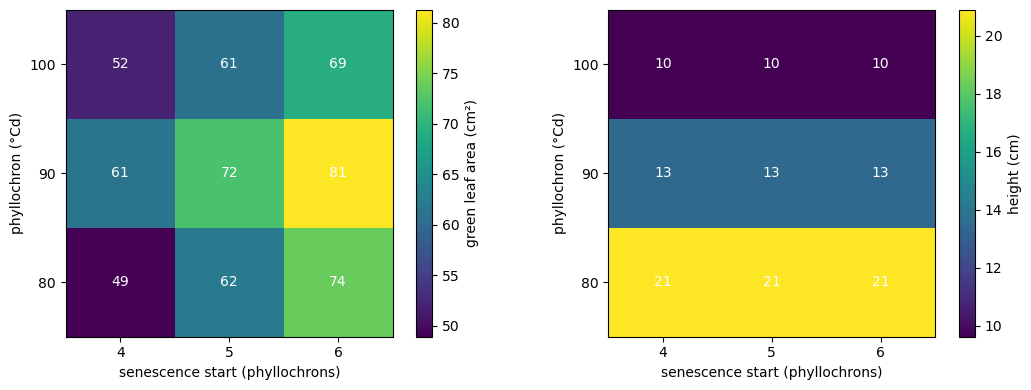

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, table, label in ((axes[0], area, "green leaf area (cm²)"), (axes[1], height, "height (cm)")):
    image = ax.imshow(table.values, origin="lower", cmap="viridis")
    ax.set_xticks(range(len(senescence_starts)), [f"{v:.0f}" for v in senescence_starts])
    ax.set_yticks(range(len(phyllochrons)), [f"{v:.0f}" for v in phyllochrons])
    ax.set_xlabel("senescence start (phyllochrons)"); ax.set_ylabel("phyllochron (°Cd)")
    for (i, j), value in np.ndenumerate(table.values):
        ax.text(j, i, f"{value:.0f}", ha="center", va="center", color="w")
    fig.colorbar(image, ax=ax, label=label)
plt.tight_layout()

**Reading the maps.**

- The **height** changes from row to row only: it depends on the phyllochron, not on the blades' senescence. With
  slower leaves, the stem elongates later.
- The **green leaf area** depends on both, and not simply. A later senescence (to the right) always keeps more leaves
  green. Along the phyllochron (upwards), the area first rises, then falls. A short phyllochron gives more leaves, but
  since senescence is counted in phyllochrons, they also senesce sooner. A long one gives fewer leaves.
- The two parameters **interact**: delaying senescence from 4 to 6 phyllochrons adds 25 cm² when the phyllochron is
  80 °Cd, where many leaves are old enough to senesce, and 17 cm² when it is 100 °Cd.

An interaction like this cannot be seen by changing one parameter at a time.

## 3. The same with lines

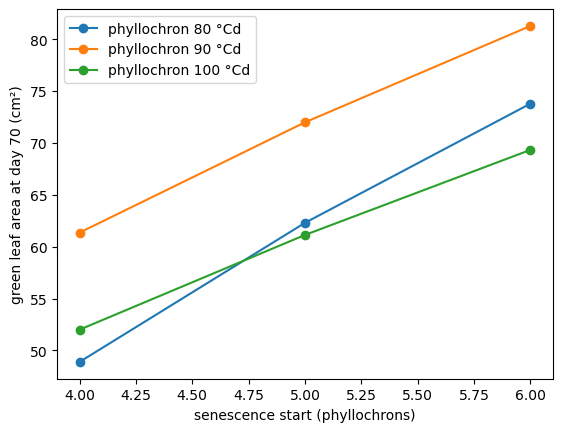

In [4]:
for phyllochron, rows_of_phyllochron in grid.groupby("phyllochron"):
    plt.plot(rows_of_phyllochron["senescence_start"], rows_of_phyllochron["green_leaf_area"] * 1e4, marker="o",
             label=f"phyllochron {phyllochron:.0f} °Cd")
plt.xlabel("senescence start (phyllochrons)"); plt.ylabel("green leaf area at day 70 (cm²)"); plt.legend();

## Try it yourself

1. Replace `senescence_start` by `senescence_duration` (2, 3, 4 phyllochrons). Does it interact with the
   phyllochron too?
2. Read the outputs at day 50 instead of 70. Does the interaction remain?
3. A grid of 5 × 5 values costs 25 simulations, and adding a third parameter multiplies it again. This is why the next
   tutorial uses cleverer designs.

**Next:** `04_sensitivity_analysis.ipynb`.